In [68]:
import pandas as pd
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn import preprocessing
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, StratifiedKFold
from sklearn.linear_model import LinearRegression, LogisticRegression, ElasticNetCV, ElasticNet, Ridge, Lasso
import statsmodels.api as sm
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from statsmodels.formula.api import mnlogit
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.metrics import balanced_accuracy_score
from matplotlib.colors import ListedColormap
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.svm import LinearSVC, LinearSVR, SVC, SVR
from sklearn import svm
from sklearn.metrics import mean_absolute_error, r2_score

In [10]:
db_null = pd.read_csv('D:/!РАБОТА/Statistic/DB/Mall_Customers.csv')

In [11]:
db_null = db_null.drop(['CustomerID'], axis=1)
print(db_null)

      Genre  Age  Annual Income (k$)  Spending Score (1-100)
0      Male   19                  15                      39
1      Male   21                  15                      81
2    Female   20                  16                       6
3    Female   23                  16                      77
4    Female   31                  17                      40
..      ...  ...                 ...                     ...
195  Female   35                 120                      79
196  Female   45                 126                      28
197    Male   32                 126                      74
198    Male   32                 137                      18
199    Male   30                 137                      83

[200 rows x 4 columns]


In [12]:
db_onehot = db_null.copy()
db_onehot = db_onehot.astype({'Genre': 'category'})
encoder = OneHotEncoder(drop = 'first')
encoded_data = encoder.fit_transform(db_onehot[['Genre']]).toarray()
encoded_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(['Genre']))
db_onehot = pd.concat([db_onehot, encoded_df], axis = 1)
db_onehot.drop('Genre', axis = 1, inplace = True)
db_onehot

,Age,Annual Income (k$),Spending Score (1-100),Genre_Male
0,19,15,39,1.0
1,21,15,81,1.0
2,20,16,6,0.0
3,23,16,77,0.0
4,31,17,40,0.0
...,...,...,...,...
195,35,120,79,0.0
196,45,126,28,0.0
197,32,126,74,1.0
198,32,137,18,1.0


In [17]:
x = x.to_numpy()
y = y.astype('int32')

In [32]:
# GridSearch для поиска гиперпараметров для модели SVC с нелинейным ядром
x = db_onehot[['Annual Income (k$)', 'Age']]
y = db_onehot['Spending Score (1-100)']
x = x.to_numpy()
y = y.astype('int32')
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1,  random_state=0) .

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)  # обучающая выборка
x_test_scaled = scaler.transform(x_test)        # тестовая выборка (только transform!)


param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'epsilon': [0.001, 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'degree' : [1, 2, 3]
}

grid = GridSearchCV(SVR(), param_grid, cv=5, scoring='r2')
grid.fit(x_train_scaled, y_train)
print("Лучшие параметры:", grid.best_params_)

Лучшие параметры: {'C': 100, 'degree': 1, 'epsilon': 1, 'kernel': 'rbf'}


In [33]:
# Так как оптимальное ядро - это rbf, то для него также можно подобрать параметр gamma

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'epsilon': [0.001, 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma':  ['scale', 0.001, 0.01, 0.1, 1],
    'degree' : [1, 2, 3]
}

grid = GridSearchCV(SVR(), param_grid, cv=5, scoring='r2')
grid.fit(x_train_scaled, y_train)
print("Лучшие параметры:", grid.best_params_)

Лучшие параметры: {'C': 10, 'degree': 1, 'epsilon': 1, 'gamma': 1, 'kernel': 'rbf'}


In [153]:
# Теперь построим модель на основе SVR

x = db_onehot[['Annual Income (k$)', 'Age']]
y = db_onehot['Spending Score (1-100)']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state=0) 

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)  # обучающая выборка
x_test_scaled = scaler.transform(x_test)        # тестовая выборка (только transform!)

model_SVR = SVR(C = 10, epsilon = 1, gamma = 1, kernel = 'rbf', degree = 1)
model_SVR.fit(x_train_scaled, y_train)
y_pred = model_SVR.predict(x_test_scaled)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Среднеквадратическая ошибка: {mse}')
print(f'R^2 Score: {r2}')
print (f'Коэффициент b модели: { model_SVR.intercept_}')
print('----------------------------------------------------')


# Опорные векторы (точки, влияющие на модель)
support_vectors = model_SVR.support_vectors_

# Их индексы в исходных данных
support_indices = model_SVR.support_


# Коэффициенты дуальной задачи (веса опорных векторов)
dual_coef = model_SVR.dual_coef_

print("Число опорных векторов:", len(support_vectors))
# print("Веса опорных векторов:", dual_coef.ravel())

print('----------------------------------------------------')
y_pred = model_SVR.predict(x_test_scaled)
print(f"MSE: {mean_squared_error(y_test, y_pred):.3f}")
# print(f"RMSE: {mean_squared_error(y_test, y_pred, squared=False):.3f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.3f}")
print(f"R²: {r2_score(y_test, y_pred):.2f}")

print(model_SVR.get_params())


Среднеквадратическая ошибка: 360.5477190193256
R^2 Score: 0.49199133608416523
Коэффициент b модели: [42.96963114]
----------------------------------------------------
Число опорных векторов: 169
----------------------------------------------------
MSE: 360.548
MAE: 14.307
R²: 0.49
{'C': 10, 'cache_size': 200, 'coef0': 0.0, 'degree': 1, 'epsilon': 1, 'gamma': 1, 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [154]:
x_test_scaled

array([[-1.44345675,  0.95098901],
       [ 1.00013205,  0.0940277 ],
       [ 0.08378625,  1.09381589],
       [ 0.0074241 ,  0.66533524],
       [ 1.03831312, -0.83434705],
       [ 1.42012387,  0.52250835],
       [-1.6725432 , -1.19141426],
       [ 0.6183213 ,  0.66533524],
       [-1.55799998,  1.37946966],
       [ 0.65650237,  0.37968147],
       [-0.56529203, -1.40565459],
       [ 0.35105377, -0.54869328],
       [ 1.3819428 , -0.12021263],
       [ 0.65650237,  0.59392179],
       [-0.25984343,  1.30805622],
       [-1.63436213, -1.12000082],
       [-1.061646  , -1.47706803],
       [ 0.38923485,  0.59392179],
       [-1.02346493, -0.62010672],
       [-0.25984343,  1.4508831 ]])

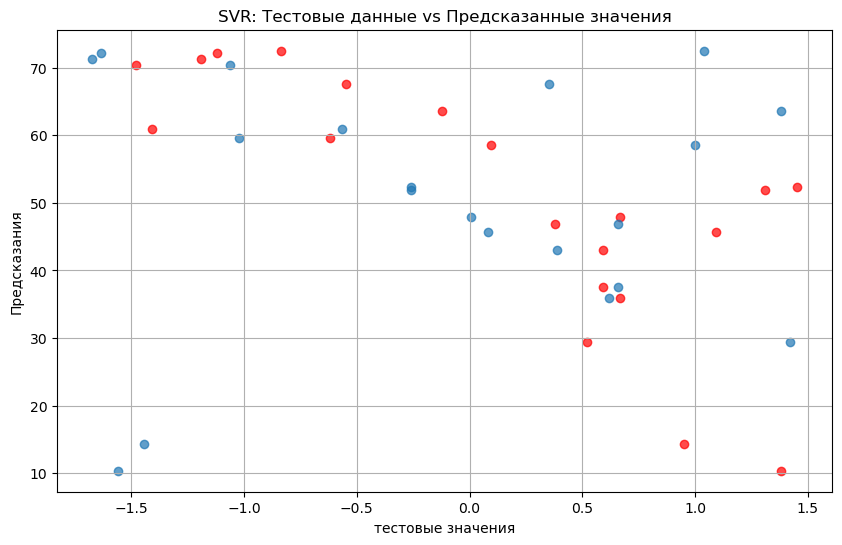

In [155]:
plt.figure(figsize=(10, 6))
plt.scatter(x_test_scaled[:,1], y_pred, alpha=0.7, c='r') # Доход
plt.scatter(x_test_scaled[:,0], y_pred, alpha=0.7) # Возраст
# plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("тестовые значения")
plt.ylabel("Предсказания")
plt.title("SVR: Тестовые данные vs Предсказанные значения")
plt.grid()
plt.show()

In [156]:
# построим модель на основе SVR на линейном ядре (для сравнения с ядром rbf

# x = db_onehot[['Annual Income (k$)', 'Age']]
# y = db_onehot['Spending Score (1-100)']

# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state=0) 

# scaler = StandardScaler()

# x_train_scaled = scaler.fit_transform(x_train)  # обучающая выборка
# x_test_scaled = scaler.transform(x_test)        # тестовая выборка (только transform!)

# model_SVR = SVR(C = 10, epsilon = 1, gamma = 1, kernel = 'linear', degree = 1)
# model_SVR.fit(x_train_scaled, y_train)
# y_pred = model_SVR.predict(x_test_scaled)

# mse = mean_squared_error(y_test, y_pred)
# r2 = r2_score(y_test, y_pred)

# print(f'Среднеквадратическая ошибка: {mse}')
# print(f'R^2 Score: {r2}')
# print (f'Коэффициенты модели: {model_SVR.coef_, model_SVR.intercept_}')
# print('----------------------------------------------------')
# print('----------------------------------------------------')
# y_pred = model_SVR.predict(x_test_scaled)
# print(f"MSE: {mean_squared_error(y_test, y_pred):.3f}")
# # print(f"RMSE: {mean_squared_error(y_test, y_pred, squared=False):.3f}")
# print(f"MAE: {mean_absolute_error(y_test, y_pred):.3f}")
# print(f"R²: {r2_score(y_test, y_pred):.3f}")

In [81]:
# Вычисление важности признаков
perm_importance = permutation_importance(
    estimator=model_SVR,
    X=x_test_scaled,
    y=y_test,
    n_repeats=10,           # число перестановок для каждого признака
    random_state=42,
    scoring='neg_mean_squared_error'  # метрика качества (можно использовать 'r2', 'neg_mean_absolute_error' и др.)
)

# Средние значения важности
importances_mean = perm_importance.importances_mean

# Стандартные отклонения
importances_std = perm_importance.importances_std

# Индексы признаков, отсортированные по важности
sorted_idx = importances_mean.argsort()[::-1]  # убывание

# Вывод результатов
feature_names = ['Annual Income (k$)', 'Age']  # замените на свои

print("Важность признаков (по убыванию):")
for idx in sorted_idx:
    print(f"{feature_names[idx]}: {importances_mean[idx]:.4f} ± {importances_std[idx]:.4f}")

Важность признаков (по убыванию):
Age: 662.5734 ± 214.5614
Annual Income (k$): 109.0819 ± 76.2464


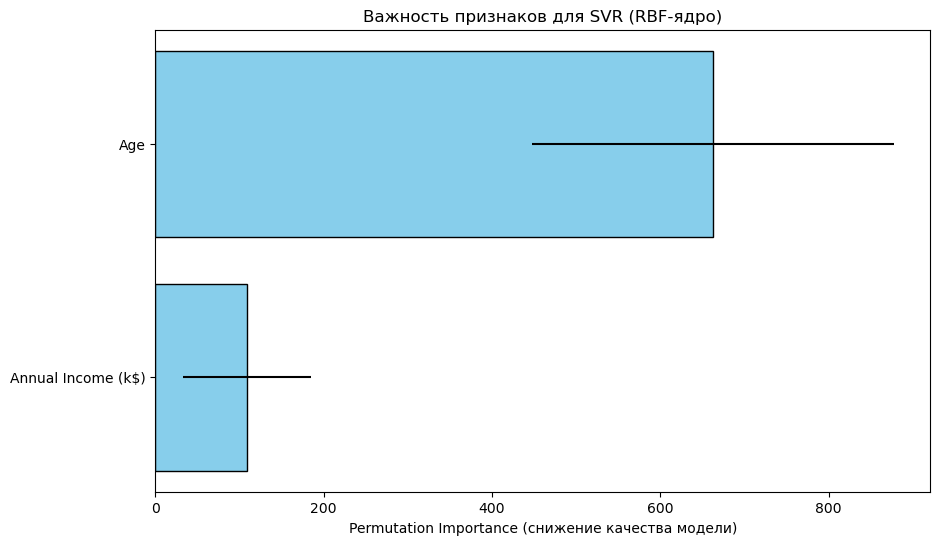

In [82]:
# Визуализация
plt.figure(figsize=(10, 6))
plt.barh(
    [feature_names[i] for i in sorted_idx],
    importances_mean[sorted_idx],
    xerr=importances_std[sorted_idx],
    color='skyblue',
    edgecolor='black'
)
plt.xlabel('Permutation Importance (снижение качества модели)')
plt.title('Важность признаков для SVR (RBF-ядро)')
plt.gca().invert_yaxis()  # сортировка от самого важного
plt.show()

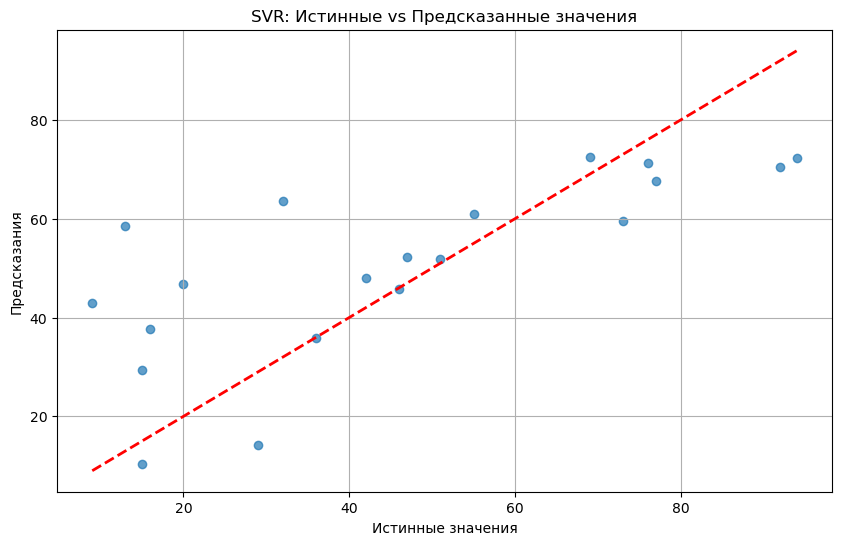

In [85]:
# Визуализация предсказаний
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Истинные значения")
plt.ylabel("Предсказания")
plt.title("SVR: Истинные vs Предсказанные значения")
plt.grid()
plt.show()

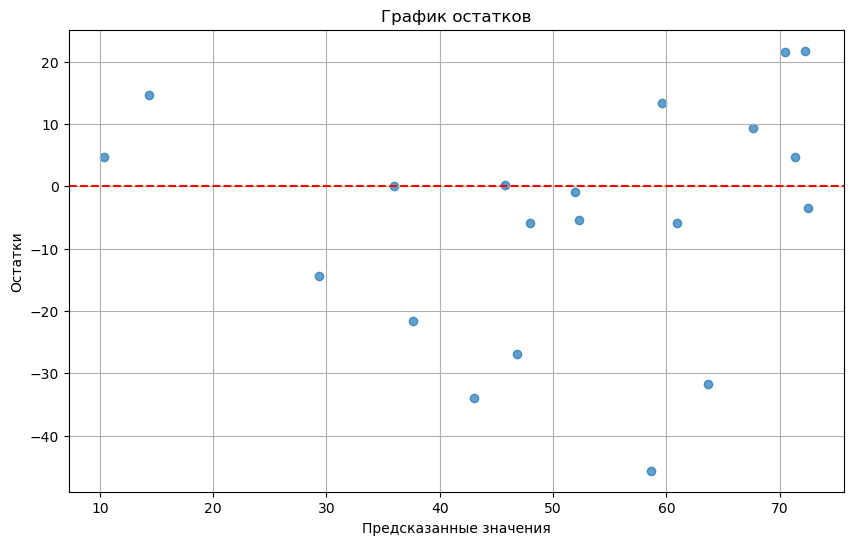

In [87]:
# Визуализация остатков
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Предсказанные значения")
plt.ylabel("Остатки")
plt.title("График остатков")
plt.grid()
plt.show()

In [89]:
# Проверка на переобучение
train_r2 = model_SVR.score(x_train_scaled, y_train)
test_r2 = model_SVR.score(x_test_scaled, y_test)
print(f"R² (train): {train_r2:.3f}")
print(f"R² (test): {test_r2:.3f}")
print(f"Разница: {train_r2 - test_r2:.3f}")


R² (train): 0.378
R² (test): 0.492
Разница: -0.114


In [115]:
y__pred = model_SVR.predict([[0.6,0.7]])
y__pred

array([35.33076465])

In [170]:
new_data = scaler.transform([[126, 32]])
y__pred_2 = model_SVR.predict(new_data)
y__pred_2                            

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([55.39077031])

In [165]:
x_train['Age']

183    29
145    28
45     24
159    30
60     70
       ..
67     68
192    33
117    49
47     27
172    36
Name: Age, Length: 180, dtype: int64

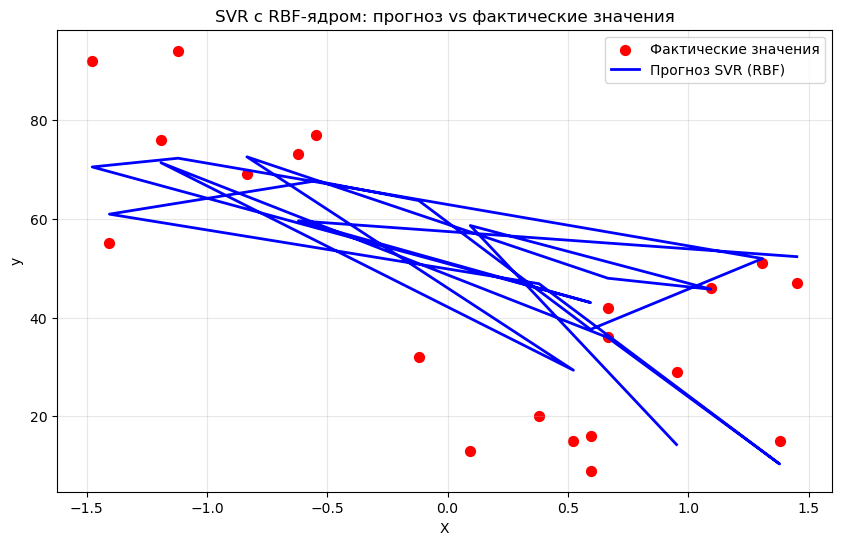

In [167]:
plt.figure(figsize=(10, 6))

# Реальные тестовые точки
plt.scatter(x_test_scaled[:, 1], y_test, color='red', label='Фактические значения', s=50)


# Предсказания модели
plt.plot(x_test_scaled[:, 1], y_pred, color='blue', linewidth=2, label='Прогноз SVR (RBF)')


# Добавляем обучающие точки (для контекста)
# plt.scatter(x_train['Age'], y_train, color='gray', alpha=0.5, s=30, label='Обучающие данные')


plt.title('SVR с RBF‑ядром: прогноз vs фактические значения')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


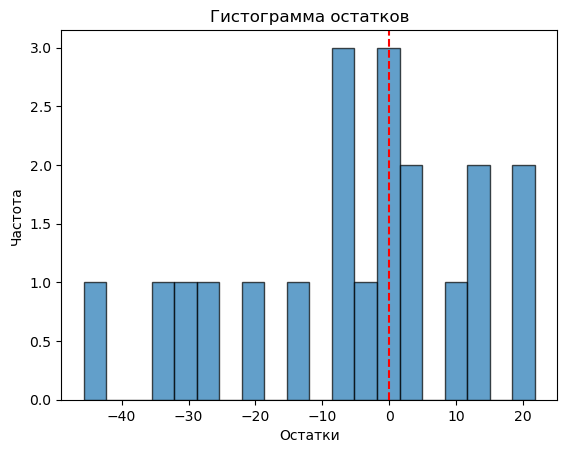

In [168]:
# Гистограмма остатков
plt.hist(residuals, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('Остатки')
plt.ylabel('Частота')
plt.title('Гистограмма остатков')
plt.axvline(0, color='red', linestyle='--')
plt.show()

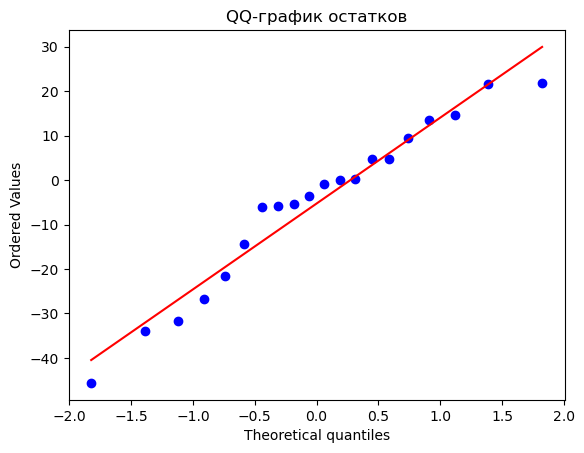

In [169]:
from scipy import stats
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('QQ‑график остатков')
plt.show()
